In [5]:
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from datetime import date
import re
from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata
from scipy.spatial.distance import jaccard, euclidean, cosine
import functools
import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix

today = date.today()

In [43]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    return fig

**Comparing OOE values for top and second regions**

In [30]:
DHS_ooe = np.load('/home/ctrader/region_similarity/data/regions_25kb_CT20220613.DHSoee.npy')
TF_ooe = np.load('/home/ctrader/region_similarity/data/regions_25kb_CT20220613.TFoee.npy')
epilogos_ooe = np.load('/home/ctrader/region_similarity/data/regions_25kb_CT20220613.epilogosoee.npy')

In [149]:
DHS_hdf5 = h5py.File(DHS_hdf5_path, 'r')
DHS_scaled_vals_full = DHS_hdf5['top_1000_scaled_vals'][:]
DHS_cosine_vals_full = DHS_hdf5['top_1000_cosine_vals'][:]
DHS_hdf5.close()

TF_hdf5 = h5py.File(TF_hdf5_path, 'r')
TF_scaled_vals_full = TF_hdf5['top_1000_scaled_vals'][:]
TF_cosine_vals_full = TF_hdf5['top_1000_cosine_vals'][:]
TF_hdf5.close()

epilogos_hdf5 = h5py.File(epilogos_hdf5_path, 'r')
epilogos_scaled_vals_full = epilogos_hdf5['top_1000_scaled_vals'][:]
epilogos_cosine_vals_full = epilogos_hdf5['top_1000_cosine_vals'][:]
epilogos_hdf5.close()

In [8]:
DHS_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220613.DHScosine.hdf5'
TF_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220613.TFcosine.hdf5'
epilogos_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220613.epilogoscosine.hdf5'
regions_path = '/home/ctrader/region_similarity/data/Altius_25kb_hg38_maxMean_CT20220613.sorted.c1t3.bed'
gz_file_path = '/home/ctrader/region_similarity/data/Altius_25kb_hg38_maxMean_CT20220613.sorted.c1t3.rownum4.bed.gz'

In [13]:
def combine_scores(DHS_count_scaled_vals, DHS_count_similar_regions, TF_count_scaled_vals, TF_count_similar_regions, epilogos_score_scaled_vals, epilogos_score_similar_regions):
    #max ind for combined score array
    max_ind = np.max([DHS_count_similar_regions, TF_count_similar_regions, epilogos_score_similar_regions])
    #DHS scores
    DHS_arr = np.zeros(max_ind + 1)
    DHS_arr[DHS_count_similar_regions] = DHS_count_scaled_vals
    #epilogos scores
    epilogos_arr = np.zeros(max_ind + 1)
    epilogos_arr[epilogos_score_similar_regions] = epilogos_score_scaled_vals
    #TF motif scores
    TF_arr = np.zeros(max_ind + 1)
    TF_arr[TF_count_similar_regions] = TF_count_scaled_vals

    #scoring all metrics
    score_arr = 1 - ((1 - epilogos_arr) * (1 - DHS_arr) * (1 - TF_arr))
    
    ##labeling most contributing metrics for each region
    contributing_cosine_arr = np.argmax(np.vstack((DHS_arr, TF_arr, epilogos_arr)), axis=0)#

    return score_arr, contributing_cosine_arr

def region_return(score_arr, contributing_cosine_arr, roi, regions_path):
    #top 100 region inds and scores
    rec_inds = np.argsort(-score_arr)[:100]
    top_region_inds = np.append(roi, rec_inds)
    top_region_scores = np.append(1, score_arr[rec_inds])
    
    #most contributing metrics to the top 100 scoring regions
    top_region_contributions = np.append('ROI', contributing_cosine_arr[rec_inds])
    top_region_contributions = np.where(top_region_contributions=='0', 'DHS', top_region_contributions)
    top_region_contributions = np.where(top_region_contributions=='1', 'TF', top_region_contributions)
    top_region_contributions = np.where(top_region_contributions=='2', 'epilogos', top_region_contributions)
    
    #combining scores and contributions
    score_contribution_comb = np.char.add(np.char.add(np.round(top_region_scores, 4).astype(str), 
                                                      np.array([' - ']*len(top_region_scores))), 
                                          top_region_contributions)
    #find genomic locations
    f = open(regions_path, 'r')
    regions = f.readlines()
    top_regions = []
    for ind in top_region_inds:
        top_regions.append(regions[ind].strip().split())
    f.close()
    top_regions = np.array(top_regions)
    top_regions = np.hstack((top_regions, score_contribution_comb.reshape((len(score_contribution_comb), 1))))#

    link_path, bed_path_name = roi_url(roi, top_regions)
    print(link_path, flush=True)

    return bed_path_name, top_region_inds

def roi_url(roi, top_regions):
    today = date.today()
    roi_url_name = 'region_comparison_recommended_regions_roi_'+str(roi)+'_scale_250kb_CT' + today.strftime("%Y%m%d") + '.bed'
    bed_path_name = os.path.join('/home/ctrader/public_html/', roi_url_name)
    np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
    link_path = 'https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg38&model=18&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roi_url_name
    return link_path, bed_path_name

In [245]:
#find roi
genomic_location = 'chr20:19756800-19756801'
gz_tb = tabix.open(gz_file_path)
roi = int(list(gz_tb.querys(genomic_location))[0][3])

# #determine roi
# roi=12345

In [246]:
print('roi = ' + str(roi), flush=True)
t = time.time()
###Load rank and ind arrays
#DHS counts
DHS_hdf5 = h5py.File(DHS_hdf5_path, 'r')
DHS_count_scaled_vals = DHS_hdf5['top_1000_scaled_vals'][roi]
DHS_count_similar_regions = DHS_hdf5['top_1000_similar_regions'][roi]
DHS_hdf5.close()

#TF motif counts
TF_hdf5 = h5py.File(TF_hdf5_path, 'r')
TF_count_scaled_vals = TF_hdf5['top_1000_scaled_vals'][roi]
TF_count_similar_regions = TF_hdf5['top_1000_similar_regions'][roi]
TF_hdf5.close()

#epilogos score sum and max
epilogos_hdf5 = h5py.File(epilogos_hdf5_path, 'r')
epilogos_score_scaled_vals = epilogos_hdf5['top_1000_scaled_vals'][roi]
epilogos_score_similar_regions = epilogos_hdf5['top_1000_similar_regions'][roi]
epilogos_hdf5.close()

###Combine scores 
#
score_arr, contributing_cosine_arr = combine_scores(DHS_count_scaled_vals, DHS_count_similar_regions, TF_count_scaled_vals, TF_count_similar_regions, epilogos_score_scaled_vals, epilogos_score_similar_regions)


###Return regions
bed_path_name, top_region_inds = region_return(score_arr, contributing_cosine_arr, roi, regions_path)
print(time.time()-t)

roi = 44127
https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg38&model=18&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fregion_comparison_recommended_regions_roi_44127_scale_250kb_CT20220614.bed
0.041629791259765625


In [247]:
max_ind = np.max([DHS_count_similar_regions, TF_count_similar_regions, epilogos_score_similar_regions])
#DHS scores
DHS_arr = np.zeros(max_ind + 1)
DHS_arr[DHS_count_similar_regions] = DHS_count_scaled_vals
#epilogos scores
epilogos_arr = np.zeros(max_ind + 1)
epilogos_arr[epilogos_score_similar_regions] = epilogos_score_scaled_vals
#TF motif scores
TF_arr = np.zeros(max_ind + 1)
TF_arr[TF_count_similar_regions] = TF_count_scaled_vals

In [248]:
def breakdown_score(ind):
    DHS_ooe_1v2 = DHS_ooe[top_region_inds[[0, ind]]]
    TF_ooe_1v2 = TF_ooe[top_region_inds[[0, ind]]]
    epilogos_ooe_1v2 = epilogos_ooe[top_region_inds[[0, ind]]]

    #cosine similarity
    print('ROI =', roi)
    print('#%s in ROIurl' %(ind+1))
    print()
    print('DHS Cosine Similarity =', np.round(cosine_similarity(DHS_ooe_1v2[0].reshape(1, -1), DHS_ooe_1v2[1].reshape(1, -1))[0, 0], 4))
    print('TF Cosine Similarity =', np.round(cosine_similarity(TF_ooe_1v2[0].reshape(1, -1), TF_ooe_1v2[1].reshape(1, -1))[0, 0], 4))
    print('Epilogos Cosine Similarity =', np.round(cosine_similarity(epilogos_ooe_1v2[0].reshape(1, -1), epilogos_ooe_1v2[1].reshape(1, -1))[0, 0], 4))
    print()
    print('1000th DHS Cosine Similarity for ROI =', np.round(DHS_cosine_vals_full[roi, -1], 4))
    print('1000th TF Cosine Similarity for ROI =', np.round(TF_cosine_vals_full[roi, -1], 4))
    print('1000th Epilogos Cosine Similarity for ROI =', np.round(epilogos_cosine_vals_full[roi, -1], 4))
    print()
    print('DHS Scaled Score =', np.round(DHS_arr[top_region_inds[ind]], 4))
    print('TF Scaled Score =', np.round(TF_arr[top_region_inds[ind]], 4))
    print('Epilogos Scaled Score =', np.round(epilogos_arr[top_region_inds[ind]], 4))
    print()
    print('Total Score =', 
          np.round(1 - ((1-DHS_arr[top_region_inds[ind]])*(1-TF_arr[top_region_inds[ind]])*(1-epilogos_arr[top_region_inds[ind]])), 4))
    print()

    #plot
    fig = plt.figure(figsize=(8,8))
    fig.patch.set_facecolor('white')

    size=30

    plt.scatter(DHS_ooe_1v2[0], DHS_ooe_1v2[1], c='#1f77b4', s=size)
    plt.scatter(TF_ooe_1v2[0], TF_ooe_1v2[1], c='#ff7f0e', s=size)
    plt.scatter(epilogos_ooe_1v2[0, :18], epilogos_ooe_1v2[1, :18], c='#2ca02c', s=size)
    plt.scatter(epilogos_ooe_1v2[0, 18:], epilogos_ooe_1v2[1, 18:], marker='x', c='#2ca02c', s=size)


    plt.xlim([np.min([np.min(DHS_ooe_1v2), np.min(TF_ooe_1v2), np.min(epilogos_ooe_1v2)])-0.5, 
              np.max([np.max(DHS_ooe_1v2), np.max(TF_ooe_1v2), np.max(epilogos_ooe_1v2)])+0.5])
    plt.ylim([np.min([np.min(DHS_ooe_1v2), np.min(TF_ooe_1v2), np.min(epilogos_ooe_1v2)])-0.5, 
              np.max([np.max(DHS_ooe_1v2), np.max(TF_ooe_1v2), np.max(epilogos_ooe_1v2)])+0.5])

    plt.legend(['DHS Counts', 'TF Motif Counts', 'Epilogos Mean', 'Epilogos Max'])

    plt.xlabel('ROI OOE Values')
    plt.ylabel('Similar Region OOE Values')
    title='Comparing OOE Values Between ROI (%s) and Rank %s Similar Region (%s)' %(roi, ind, top_region_inds[ind])
    plt.title(title)
    print(title)

ROI = 44127
#3 in ROIurl

DHS Cosine Similarity = 0.8837
TF Cosine Similarity = 0.8899
Epilogos Cosine Similarity = 0.8364

1000th DHS Cosine Similarity for ROI = 0.841
1000th TF Cosine Similarity for ROI = 0.8855
1000th Epilogos Cosine Similarity for ROI = 0.79

DHS Scaled Score = 0.7028
TF Scaled Score = 0.8565
Epilogos Scaled Score = 0.6853

Total Score = 0.9866

Comparing OOE Values Between ROI (44127) and Rank 2 Similar Region (61726)


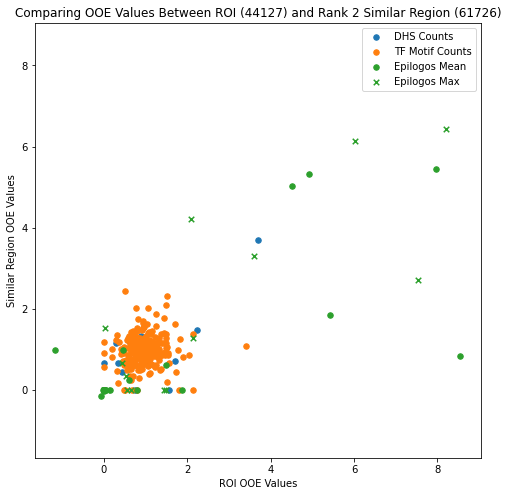

In [253]:
breakdown_score(2)

ROI = 44127
#100 in ROIurl

DHS Cosine Similarity = 0.4556
TF Cosine Similarity = 0.8311
Epilogos Cosine Similarity = 0.9382

1000th DHS Cosine Similarity for ROI = 0.841
1000th TF Cosine Similarity for ROI = 0.8855
1000th Epilogos Cosine Similarity for ROI = 0.79

DHS Scaled Score = 0.0
TF Scaled Score = 0.0
Epilogos Scaled Score = 0.8811

Total Score = 0.8811

Comparing OOE Values Between ROI (44127) and Rank 99 Similar Region (34210)


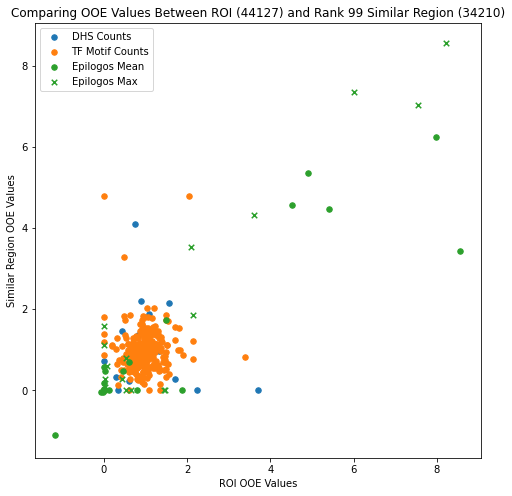

In [250]:
breakdown_score(99)